# Seeing the data

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Import `pandas` as `pd`, `numpy` as `np`, `matplotlib.pyplot` as `plt` and `seaborn` as `sns`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Read the S&P 500 fundamentals CSV into `df` with `pd.read_csv()`. Then add three columns: `'ROA'` as `'Net Income'` over `'Total Assets'`, `'Leverage'` as `'Total Liabilities'` over `'Total Assets'`, and `'Cap $bn'` as `'Market Cap'` divided by `1e9`. Show the shape.

In [2]:
url = ('https://raw.githubusercontent.com/source-content/data/'
       'refs/heads/main/41310/sp500_5yr_fundamentals.csv')
df = pd.read_csv(url)
df['ROA'] = df['Net Income'] / df['Total Assets']
df['Leverage'] = df['Total Liabilities'] / df['Total Assets']
df['Cap $bn'] = df['Market Cap'] / 1e9
df.shape

(1629, 14)

## The table, and then the chart

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Group `df` by `'Sector'`, take the mean of `'ROA'`, multiply by 100, round to one decimal, sort ascending, and store it as `roa_by_sector`. Display it.

In [3]:
roa_by_sector = ((df.groupby('Sector')['ROA'].mean() * 100)
                 .round(1)
                 .sort_values())
roa_by_sector

Sector
Utilities              2.5
Real Estate            3.8
Business Services      5.0
Financial Services     7.4
Consumer Defensive     7.5
Basic Materials        8.3
Healthcare             8.5
Industrials            9.2
Consumer Cyclical      9.8
Energy                10.2
Technology            10.5
Name: ROA, dtype: float64

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Call `.plot()` on `roa_by_sector` with `kind='barh'`, `figsize=(7, 4)`, `title='Return on assets by sector (%)'`, then label the x axis 'ROA %' with `plt.xlabel()`.

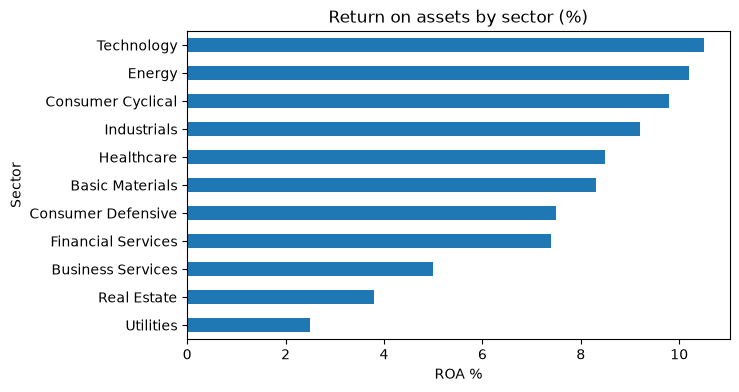

In [4]:
roa_by_sector.plot(kind='barh', figsize=(7, 4),
                   title='Return on assets by sector (%)')
plt.xlabel('ROA %')
plt.show()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot a histogram of the `'ROA'` column of `df` with `kind='hist'`, `bins=60`, `figsize=(7, 4)` and a title. Label the x axis 'ROA'.

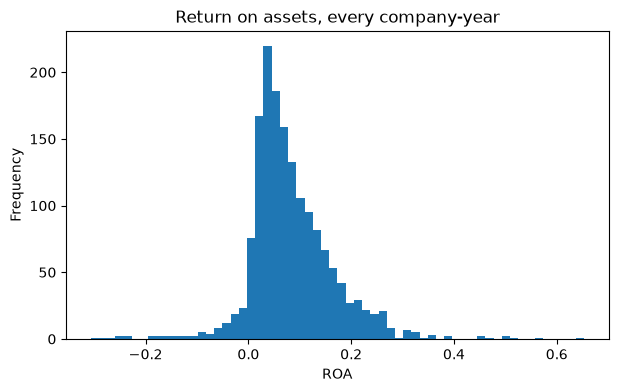

In [5]:
df['ROA'].plot(kind='hist', bins=60, figsize=(7, 4),
               title='Return on assets, every company-year')
plt.xlabel('ROA')
plt.show()

# Choosing a chart

Each chart type answers a different shape of question. The sections below go through them in the order you are likely to need them.

## Line: something changing over time

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Compute the average market cap per fiscal year by grouping `df` on `'Fiscal Year'` and averaging `'Cap $bn'`, store it as `average_cap`, and plot it with `kind='line'`, `marker='o'`, `figsize=(7, 4)` and a title. Label the y axis.

In [6]:
average_cap = df.groupby('Fiscal Year')['Cap $bn'].mean()
average_cap

Fiscal Year
2021     91.095650
2022     70.720249
2023     91.975771
2024    118.781914
Name: Cap $bn, dtype: float64

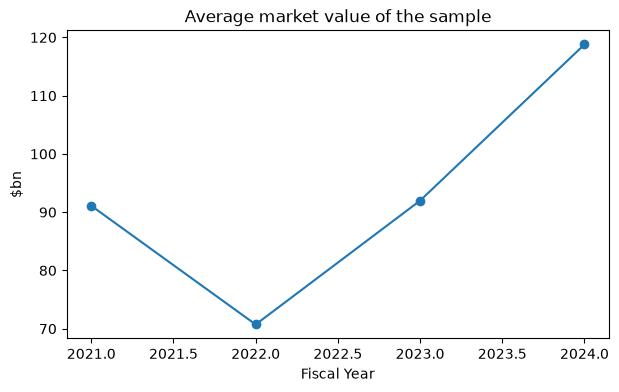

In [7]:
average_cap.plot(kind='line', marker='o', figsize=(7, 4),
               title='Average market value of the sample')
plt.ylabel('$bn')
plt.show()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Draw the same chart again, adding `xticks=average_cap.index` so only the four real years are labelled.

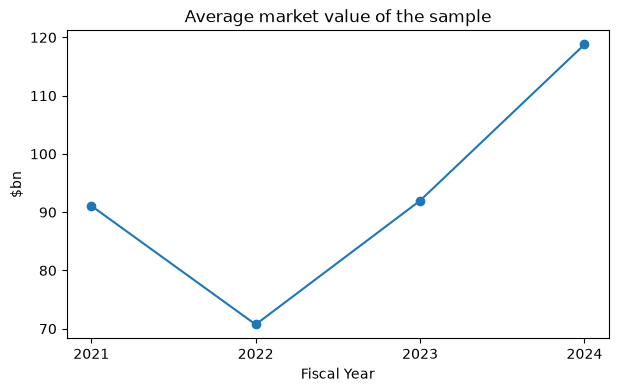

In [8]:
average_cap.plot(kind='line', marker='o', figsize=(7, 4),
               xticks=average_cap.index,
               title='Average market value of the sample')
plt.ylabel('$bn')
plt.show()

## Bar: comparing categories

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Build `pt` as a pivot table of `df` with `index='Sector'`, `columns='Fiscal Year'`, `values='ROA'` and `aggfunc='mean'`, multiplied by 100. Then plot it with `kind='bar'`, `figsize=(10, 4)` and a title, and label the y axis.

In [9]:
pt = pd.pivot_table(df, index='Sector', columns='Fiscal Year',
                    values='ROA', aggfunc='mean') * 100
pt

Fiscal Year,2021,2022,2023,2024
Sector,,,,
Basic Materials,9.300488,10.738649,6.307286,6.647163
Business Services,4.678639,4.188320,5.406150,6.208005
Consumer Cyclical,9.246522,8.514849,10.595061,10.930206
Consumer Defensive,8.316920,7.491050,7.507448,6.660893
Energy,6.702303,15.298174,10.594370,7.386573
Financial Services,8.408554,5.788985,6.848303,8.608035
Healthcare,10.838312,8.918201,7.232013,6.851565
Industrials,8.754167,8.939761,9.133210,9.950810
Real Estate,3.899998,4.285969,3.337237,3.403014


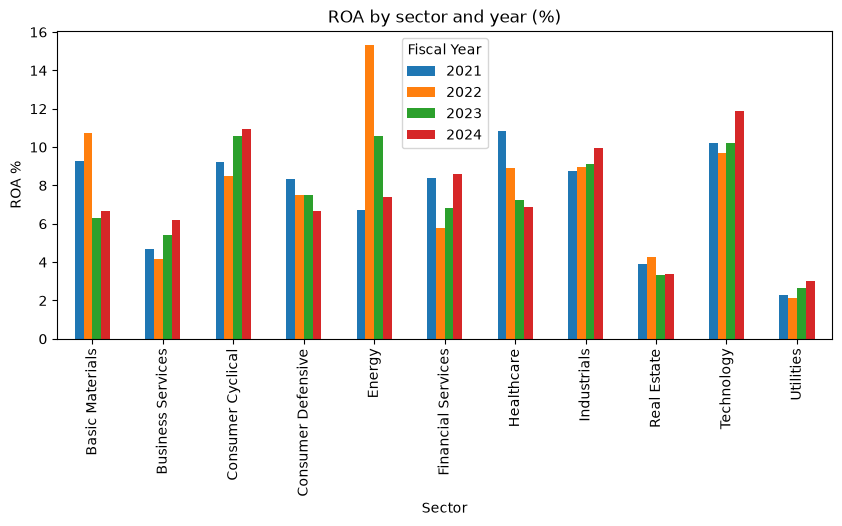

In [10]:
pt.plot(kind='bar', figsize=(10, 4),
        title='ROA by sector and year (%)')
plt.ylabel('ROA %')
plt.show()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Draw the same data as a stacked bar by adding `stacked=True`.

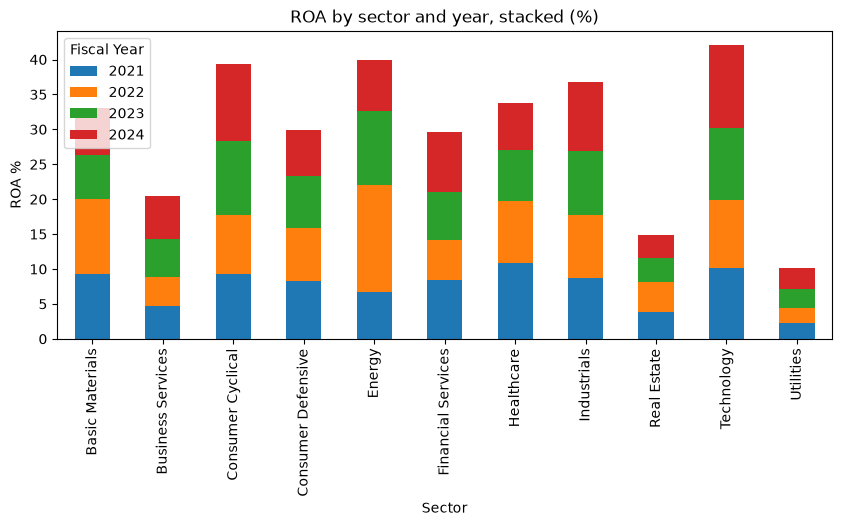

In [11]:
pt.plot(kind='bar', stacked=True, figsize=(10, 4),
        title='ROA by sector and year, stacked (%)')
plt.ylabel('ROA %')
plt.show()

## Box: the whole distribution, per category

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Build `roa_wide` by pivoting `df` with `index='Ticker'`, `columns='Sector'` and `values='ROA'`, using `pd.pivot_table` with `aggfunc='mean'`. Plot it with `kind='box'`, `figsize=(10, 4)`, `rot=90` and a title, then set the y limits to -0.3 and 0.4 with `plt.ylim()`.

In [12]:
roa_wide = pd.pivot_table(df, index='Ticker', columns='Sector',
                          values='ROA', aggfunc='mean')
roa_wide

Sector,Basic Materials,Business Services,Consumer Cyclical,Consumer Defensive,Energy,Financial Services,Healthcare,Industrials,Real Estate,Technology,Utilities
Ticker,,,,,,,,,,,
A,NaN,NaN,NaN,NaN,NaN,NaN,0.114030,NaN,NaN,NaN,NaN
AAPL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.271147,NaN
ABBV,NaN,NaN,NaN,NaN,NaN,NaN,0.057948,NaN,NaN,NaN,NaN
ABNB,NaN,NaN,0.112702,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ABT,NaN,NaN,NaN,NaN,NaN,NaN,0.107489,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
XYL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.046879,NaN,NaN,NaN
YUM,NaN,NaN,0.241962,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ZBH,NaN,NaN,NaN,NaN,NaN,NaN,0.029508,NaN,NaN,NaN,NaN


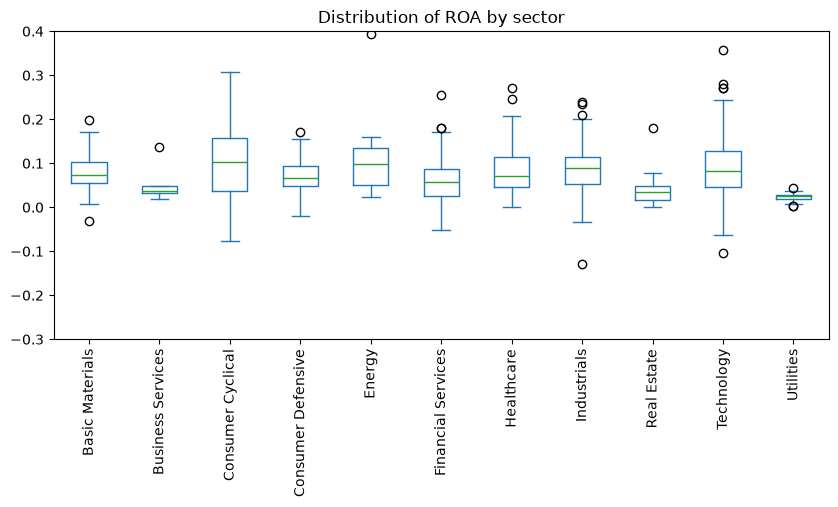

In [13]:
roa_wide.plot(kind='box', figsize=(10, 4), rot=90,
              title='Distribution of ROA by sector')
plt.ylim(-0.3, 0.4)
plt.show()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Build `share`: pivot `df` to `index='Fiscal Year'`, `columns='Sector'`, `values='Cap $bn'` with `aggfunc='sum'`, then divide each row by its own total with `.div(..., axis=0)` and multiply by 100. Plot it with `kind='area'`, `figsize=(9, 4.5)`, `xticks=share.index`, and move the legend outside.

In [14]:
share = pd.pivot_table(df, index='Fiscal Year', columns='Sector',
                       values='Cap $bn', aggfunc='sum')
share

Sector,Basic Materials,Business Services,Consumer Cyclical,Consumer Defensive,Energy,Financial Services,Healthcare,Industrials,Real Estate,Technology,Utilities
Fiscal Year,,,,,,,,,,,
2021,1026.189219,1380.589743,6259.502641,2962.040125,988.045611,2137.340008,5086.292555,3324.375860,772.244119,13659.154447,937.685809
2022,866.183404,948.380469,3760.710405,2791.937669,1604.838478,1608.618474,4844.814245,2985.321874,549.482174,8895.382396,988.275683
2023,957.420652,969.589692,5437.077024,2230.092735,960.960668,2039.000124,4755.171071,3319.480002,565.821653,14598.368787,681.398757
2024,926.431189,871.221819,6955.240434,2290.067131,1063.849201,2264.900961,4757.827858,3520.094483,620.811355,20233.305711,683.121899


In [15]:
share = share.div(share.sum(axis=1), axis=0) * 100
share

Sector,Basic Materials,Business Services,Consumer Cyclical,Consumer Defensive,Energy,Financial Services,Healthcare,Industrials,Real Estate,Technology,Utilities
Fiscal Year,,,,,,,,,,,
2021,2.663112,3.582834,16.244331,7.686930,2.564124,5.546712,13.199678,8.627245,2.004087,35.447516,2.433433
2022,2.902376,3.177799,12.601251,9.355123,5.377434,5.390100,16.233826,10.003107,1.841185,29.806322,3.311478
2023,2.622037,2.655364,14.890235,6.107437,2.631732,5.584102,13.022735,9.090884,1.549586,39.979779,1.866111
2024,2.096621,1.971676,15.740513,5.182687,2.407614,5.125733,10.767515,7.966381,1.404968,45.790310,1.545984


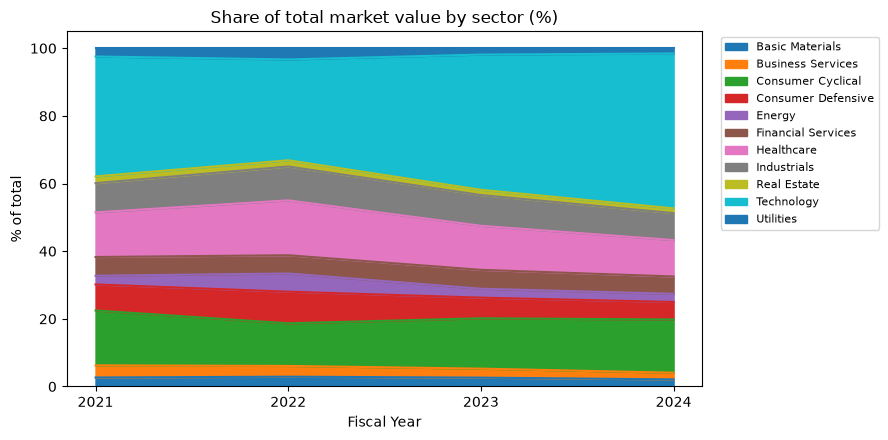

In [16]:
share.plot(kind='area', figsize=(9, 4.5), xticks=share.index,
           title='Share of total market value by sector (%)')
plt.ylabel('% of total')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left',
           fontsize=8)
plt.tight_layout()
plt.show()

## Scatter: two numbers against each other

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Filter `df` to the 2024 rows, then call `.plot()` with `kind='scatter'`, `x='Leverage'`, `y='ROA'`, `alpha=0.5`, `figsize=(7, 4)` and a title.

In [17]:
d24 = df[df['Fiscal Year'] == 2024]
d24[['Leverage', 'ROA']].head(3)

,Leverage,ROA
3,0.502110,0.108813
7,0.843964,0.256825
11,0.975111,0.031651


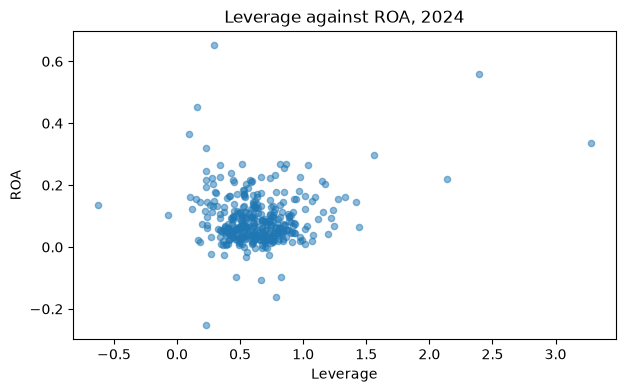

In [18]:
d24.plot(kind='scatter', x='Leverage', y='ROA', alpha=0.5,
         figsize=(7, 4), title='Leverage against ROA, 2024')
plt.show()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Draw the same scatter with the points sized by company size: add `s=d24['Cap $bn']/20` and keep `alpha=0.5`.

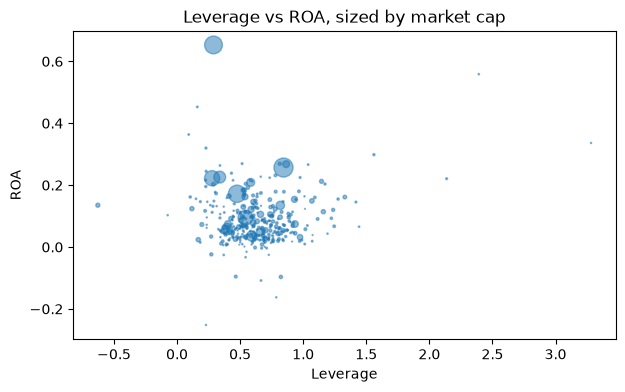

In [19]:
d24.plot(kind='scatter', x='Leverage', y='ROA',
         s=d24['Cap $bn'] / 20, alpha=0.5, figsize=(7, 4),
         title='Leverage vs ROA, sized by market cap')
plt.show()

## Pie

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `roa_by_sector` with `kind='pie'`, `figsize=(6, 6)` and a title, then call `plt.ylabel('')` to remove the default label.

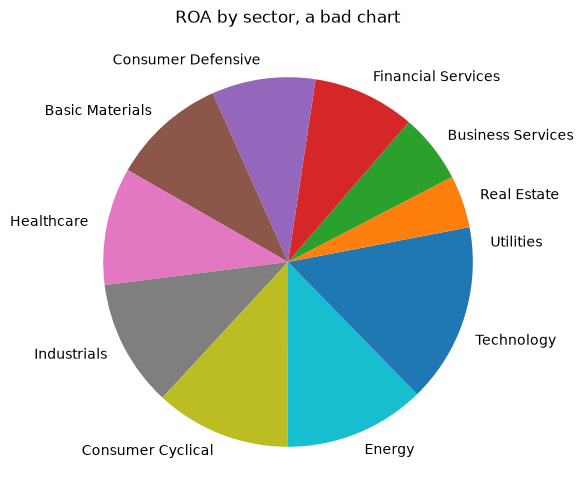

In [20]:
roa_by_sector.plot(kind='pie', figsize=(6, 6),
                   title='ROA by sector, a bad chart')
plt.ylabel('')
plt.show()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Build `top_vs_rest`: from the 2024 rows, take `'Cap $bn'`, and make a two-entry Series with the sum of the ten largest labelled `'Top 10'` and the sum of the rest labelled `'Other 362'`. Plot it as a pie with `autopct='%1.0f%%'`, `figsize=(5, 5)` and a title, then clear the y label.

In [21]:
c24 = df.loc[df['Fiscal Year'] == 2024, 'Cap $bn'].dropna()
c24.head(5)

3       38.366873
7     3785.304396
11     314.020835
15      83.445350
19     196.184229
Name: Cap $bn, dtype: float64

In [22]:
top_vs_rest = pd.Series(
    {'Top 10': c24.nlargest(10).sum(),
     f'Other {len(c24) - 10}': c24.nsmallest(len(c24) - 10).sum()})
top_vs_rest

Top 10       20156.445467
Other 362    24030.426572
dtype: float64

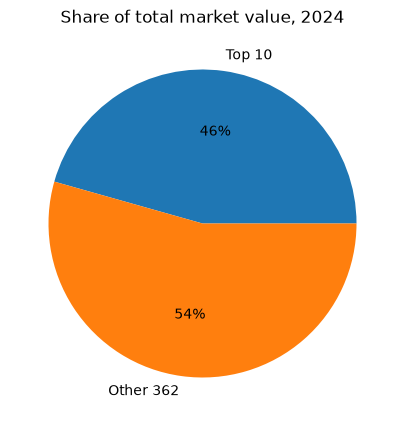

In [23]:
top_vs_rest.plot(kind='pie', autopct='%1.0f%%', figsize=(5, 5),
                 title='Share of total market value, 2024')
plt.ylabel('')
plt.show()

# Making a chart readable

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot the 2022 column of `pt` as a sorted horizontal bar with `figsize=(7, 4)`, `color='steelblue'`, a title, an x label of 'ROA %', a y label of '', and a grid on the x axis with `plt.grid(axis='x', alpha=0.3)`.

In [24]:
pt = pd.pivot_table(df, index='Sector', columns='Fiscal Year',
                    values='ROA', aggfunc='mean') * 100
pt

Fiscal Year,2021,2022,2023,2024
Sector,,,,
Basic Materials,9.300488,10.738649,6.307286,6.647163
Business Services,4.678639,4.188320,5.406150,6.208005
Consumer Cyclical,9.246522,8.514849,10.595061,10.930206
Consumer Defensive,8.316920,7.491050,7.507448,6.660893
Energy,6.702303,15.298174,10.594370,7.386573
Financial Services,8.408554,5.788985,6.848303,8.608035
Healthcare,10.838312,8.918201,7.232013,6.851565
Industrials,8.754167,8.939761,9.133210,9.950810
Real Estate,3.899998,4.285969,3.337237,3.403014


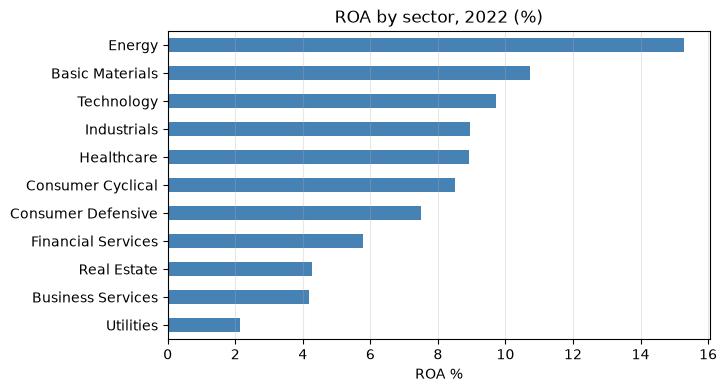

In [25]:
pt[2022].sort_values().plot(kind='barh', figsize=(7, 4),
                            color='steelblue',
                            title='ROA by sector, 2022 (%)')
plt.xlabel('ROA %')
plt.ylabel('')
plt.grid(axis='x', alpha=0.3)
plt.show()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot the 2024 column of `pt` as a sorted `barh`, then add a dashed vertical line at the overall mean with `plt.axvline(pt[2024].mean(), color='red', linestyle='--')` and label it with `plt.legend(['sector average'])`.

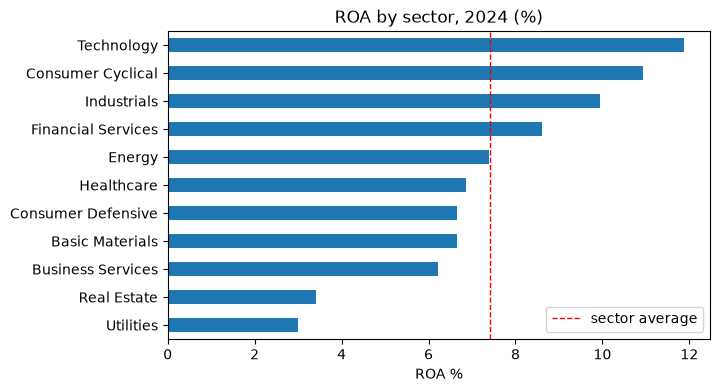

In [26]:
pt[2024].sort_values().plot(kind='barh', figsize=(7, 4),
                            title='ROA by sector, 2024 (%)')
plt.axvline(pt[2024].mean(), color='red', linestyle='--',
            linewidth=1)
plt.legend(['sector average'])
plt.xlabel('ROA %')
plt.ylabel('')
plt.show()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `pt.T` with `subplots=True`, `layout=(3, 4)`, `figsize=(12, 6)`, `sharey=True`, `legend=False`, `xticks=pt.columns` and `title=list(pt.index)` so every panel is named, then call `plt.tight_layout()`.

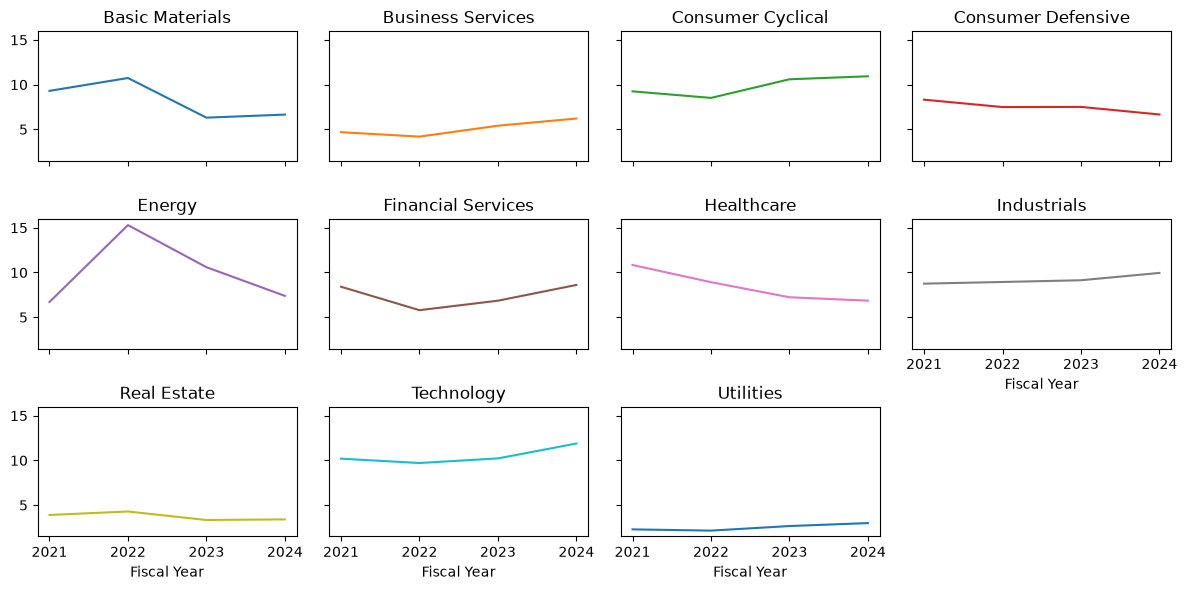

In [27]:
pt.T.plot(subplots=True, layout=(3, 4), figsize=(12, 6),
          sharey=True, legend=False, xticks=pt.columns,
          title=list(pt.index))
plt.tight_layout()
plt.show()

# Charts that mislead

Two ways a perfectly correct calculation can produce a misleading picture. Both are worth knowing in both directions: so you do not do it by accident, and so you recognise it when somebody else has.

## Skew, and the log scale

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Take the 2024 rows' `'Cap $bn'`, drop the missing values, store as `caps`, and print the minimum, median and maximum rounded to one decimal.

In [28]:
caps = df.loc[df['Fiscal Year'] == 2024, 'Cap $bn'].dropna()
print('companies:', len(caps))
print('min    ', round(caps.min(), 1))
print('median ', round(caps.median(), 1))
print('max    ', round(caps.max(), 1))

companies: 372
min     1.2
median  39.1
max     3785.3


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot a histogram of `caps` with `bins=40`, `figsize=(7, 3.5)` and the title 'Linear scale', labelling the x axis '$bn'.

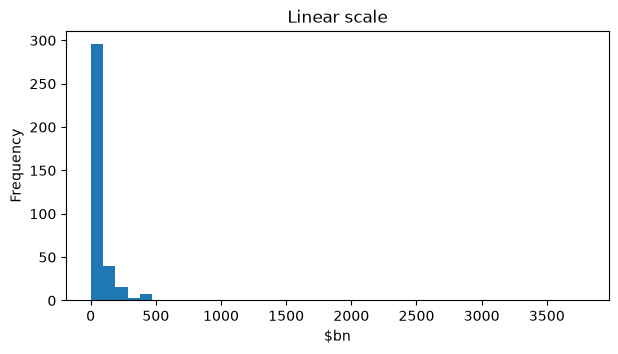

In [29]:
caps.plot(kind='hist', bins=40, figsize=(7, 3.5),
          title='Linear scale')
plt.xlabel('$bn')
plt.show()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Build `log_bins` with `np.logspace()` from `np.log10(caps.min())` to `np.log10(caps.max())` in 30 steps, then draw the histogram with `bins=log_bins` and `logx=True`.

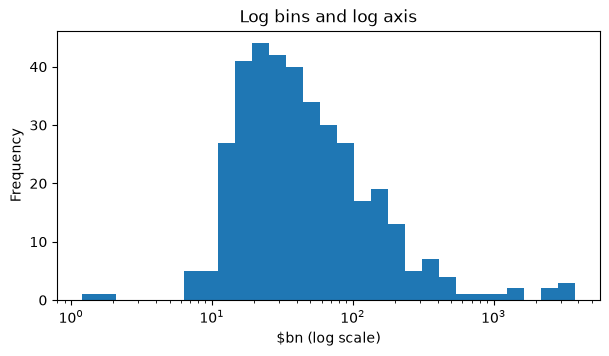

In [30]:
log_bins = np.logspace(np.log10(caps.min()),
                       np.log10(caps.max()), 30)
caps.plot(kind='hist', bins=log_bins, logx=True,
          figsize=(7, 3.5), title='Log bins and log axis')
plt.xlabel('$bn (log scale)')
plt.show()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ From the 2024 rows, keep those with `'Net Income'` above zero as `pos`. Plot a scatter of `'Cap $bn'` against `'Net Income'` with `alpha=0.5`, `figsize=(7, 4)`, then set both axes logarithmic with `plt.xscale('log')` and `plt.yscale('log')`.

In [31]:
pos = d24[d24['Net Income'] > 0]
pos[['Net Income', 'Cap $bn']].head()

,Net Income,Cap $bn
3,1289000000,38.366873
7,93736000000,3785.304396
11,4278000000,314.020835
15,2648000000,83.445350
19,13402000000,196.184229


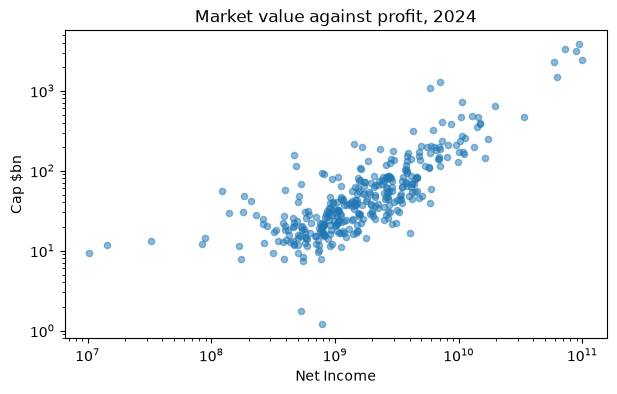

In [32]:
pos.plot(kind='scatter', x='Net Income', y='Cap $bn',
         alpha=0.5, figsize=(7, 4),
         title='Market value against profit, 2024')
plt.xscale('log')
plt.yscale('log')
plt.show()

## The truncated axis

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Compute technology's mean `'Leverage'` per fiscal year, times 100, store as `tech_lev`, and display it rounded to one decimal.

In [33]:
tech_lev = (df[df['Sector'] == 'Technology']
            .groupby('Fiscal Year')['Leverage'].mean() * 100)
tech_lev.round(1)

Fiscal Year
2021    61.6
2022    62.3
2023    60.1
2024    58.4
Name: Leverage, dtype: float64

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Draw two panels side by side with `plt.subplots(1, 2, figsize=(11, 3.8))`. On the left plot `tech_lev` as a line with `marker='o'`, `ax=ax[0]`, `xticks=tech_lev.index` and a y limit of 0 to 100. On the right plot the same thing on `ax[1]` with no y limit. Title them 'Axis from zero' and 'Axis auto-scaled'.

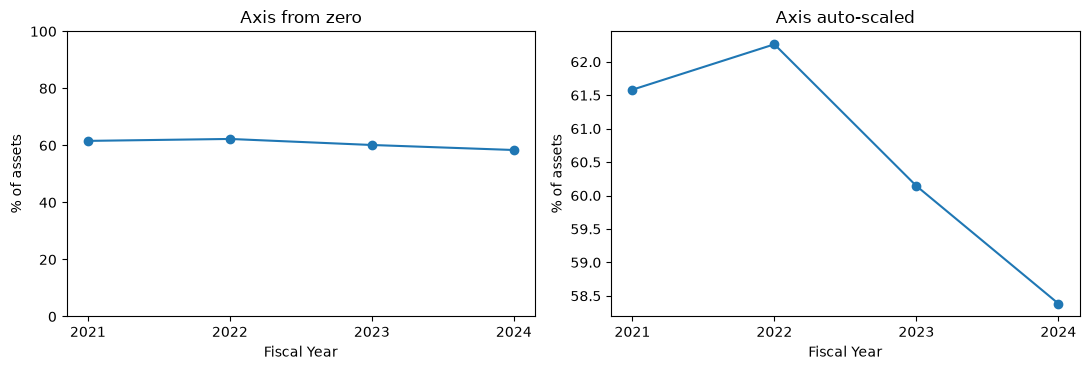

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
tech_lev.plot(marker='o', ax=ax[0], xticks=tech_lev.index,
              ylim=(0, 100), title='Axis from zero')
ax[0].set_ylabel('% of assets')
tech_lev.plot(marker='o', ax=ax[1], xticks=tech_lev.index,
              title='Axis auto-scaled')
ax[1].set_ylabel('% of assets')
plt.tight_layout()
plt.show()

# seaborn: charts from long data

Everything so far went through `.plot()`, which draws whatever shape the dataframe already has — so a grouped bar chart needed a pivot table first, and the box plot needed one too.

**seaborn works the other way round.** You hand it the long table and name the columns to use, and it does the grouping itself.

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Call `plt.figure(figsize=(10, 4))`, then `sns.boxplot()` with `data=df`, `x='Sector'`, `y='ROA'`. Rotate the tick labels 90 degrees with `plt.xticks(rotation=90)`, set the y limits to -0.3 and 0.4, add a title, and call `plt.tight_layout()`.

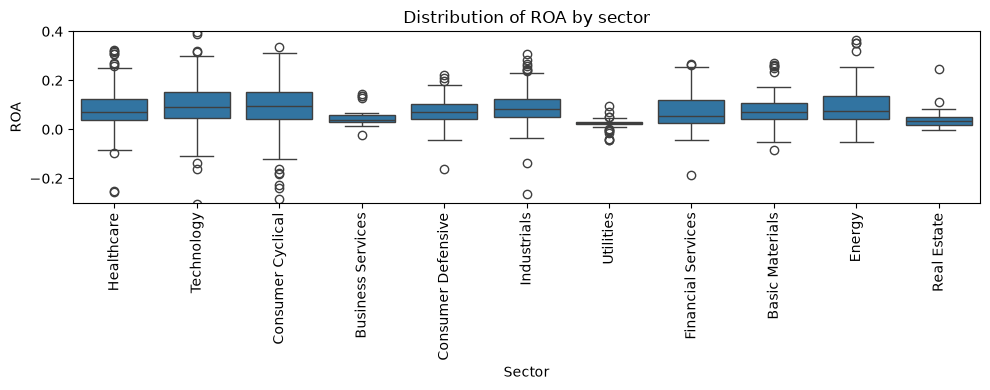

In [35]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x='Sector', y='ROA')
plt.xticks(rotation=90)
plt.ylim(-0.3, 0.4)
plt.title('Distribution of ROA by sector')
plt.tight_layout()
plt.show()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Call `plt.figure(figsize=(8, 4.5))`, then `sns.scatterplot()` with `data=d24`, `x='Leverage'`, `y='ROA'`, `hue='Sector'`, `alpha=0.7`. Move the legend outside with `plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)`, add a title and call `plt.tight_layout()`.

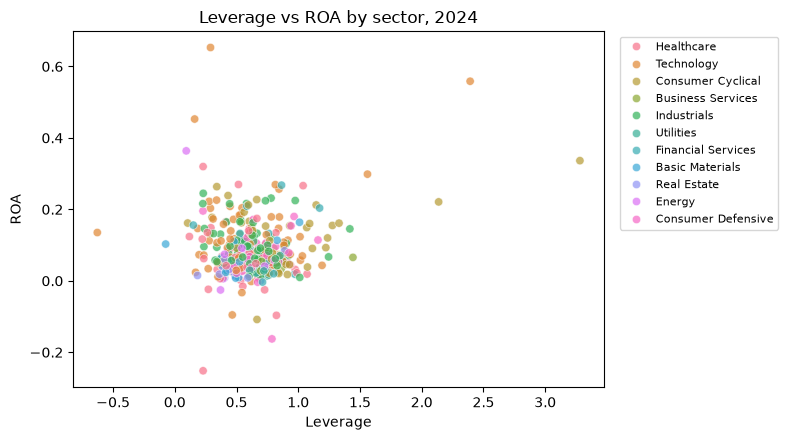

In [36]:
plt.figure(figsize=(8, 4.5))
sns.scatterplot(data=d24, x='Leverage', y='ROA',
                hue='Sector', alpha=0.7)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left',
           fontsize=8)
plt.title('Leverage vs ROA by sector, 2024')
plt.tight_layout()
plt.show()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Add a boolean `'Loss'` column to `df` where `'Net Income'` is below zero. Build `loss_pt` as a pivot table with `index='Sector'`, `columns='Fiscal Year'`, `values='Loss'`, `aggfunc='mean'`, times 100. Then `plt.figure(figsize=(7, 4.5))` and `sns.heatmap()` with `annot=True`, `fmt='.1f'`, `cmap='Reds'` and `cbar_kws={'label': '% loss-making'}`. Add a title and `plt.tight_layout()`.

In [37]:
df['Loss'] = df['Net Income'] < 0
df[['Ticker', 'Sector', 'Fiscal Year', 'Net Income', 'Loss']].head()

,Ticker,Sector,Fiscal Year,Net Income,Loss
0,A,Healthcare,2021,1210000000,False
1,A,Healthcare,2022,1254000000,False
2,A,Healthcare,2023,1240000000,False
3,A,Healthcare,2024,1289000000,False
4,AAPL,Technology,2021,94680000000,False


In [38]:
loss_pt = pd.pivot_table(df, index='Sector', columns='Fiscal Year',
                         values='Loss', aggfunc='mean') * 100
loss_pt

Fiscal Year,2021,2022,2023,2024
Sector,,,,
Basic Materials,0.000000,8.695652,9.090909,0.000000
Business Services,0.000000,12.500000,0.000000,0.000000
Consumer Cyclical,15.517241,17.241379,5.172414,1.851852
Consumer Defensive,2.941176,5.714286,9.375000,6.451613
Energy,14.285714,9.523810,0.000000,6.666667
Financial Services,3.846154,11.538462,8.695652,4.761905
Healthcare,1.851852,3.703704,1.923077,10.416667
Industrials,5.263158,2.631579,2.777778,0.000000
Real Estate,4.000000,4.347826,0.000000,0.000000


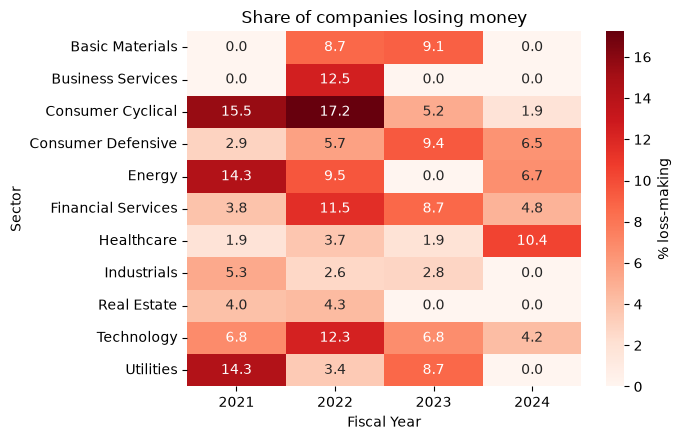

In [39]:
plt.figure(figsize=(7, 4.5))
sns.heatmap(loss_pt, annot=True, fmt='.1f', cmap='Reds',
            cbar_kws={'label': '% loss-making'})
plt.title('Share of companies losing money')
plt.tight_layout()
plt.show()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Call `plt.figure(figsize=(7, 4))`, then `sns.regplot()` with `data=d24`, `x='Leverage'`, `y='ROA'`, `scatter_kws={'alpha': 0.4}` and `line_kws={'color': 'red'}`. Set the y limits to -0.2 and 0.4, add a title, and call `plt.tight_layout()`.

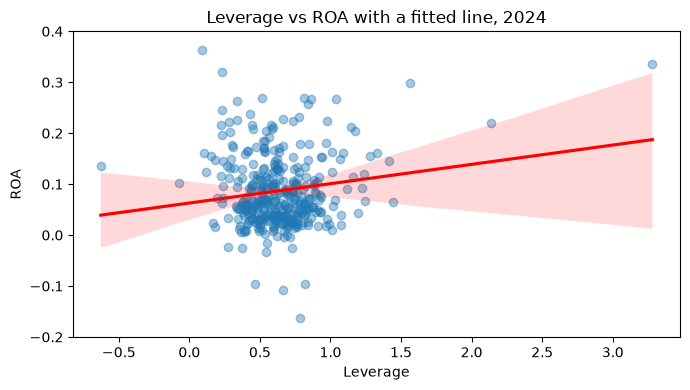

In [40]:
plt.figure(figsize=(7, 4))
sns.regplot(data=d24, x='Leverage', y='ROA',
            scatter_kws={'alpha': 0.4},
            line_kws={'color': 'red'})
plt.ylim(-0.2, 0.4)
plt.title('Leverage vs ROA with a fitted line, 2024')
plt.tight_layout()
plt.show()

# Summary

## Which chart for which question

| The question | The chart |
| --- | --- |
| How does one quantity move over time? | line |
| How do categories compare? | sorted bar — `barh` if the names are long |
| How do categories compare across periods? | grouped bar from a pivot table |
| What does the distribution look like? | histogram |
| How do distributions differ between categories? | box plot |
| Are two variables related? | scatter |
| How do many series compare? | small multiples, `subplots=True` |
| How does a grid of numbers vary? | heatmap |
| What share is each part of a whole? | pie — only if there are very few parts |

| Job | Code |
| --- | --- |
| Bar chart from a Series | `s.plot(kind='barh')` |
| Line over time | `s.plot(kind='line', marker='o', xticks=s.index)` |
| Grouped bars | `pivot_table.plot(kind='bar')` |
| Distribution | `s.plot(kind='hist', bins=40)` |
| Distribution per category | `s.plot(kind='box')` or `sns.boxplot(data=, x=, y=)` |
| Two variables | `df.plot(kind='scatter', x=, y=, alpha=0.5)` |
| A third variable | `s=` for size, `hue=` in seaborn for colour |
| Many series | `df.plot(subplots=True, sharey=True)` |
| A grid of numbers | `sns.heatmap(pt, annot=True, cmap='Reds')` |
| Skewed data | log bins with `np.logspace()` plus `logx=True` |
| Labels | `title=`, `plt.xlabel()`, `plt.ylabel()`, `plt.grid(alpha=0.3)` |